# Book Advisor Agent

This is an AI agent project.

Goodbooks-10k has titles, authors, ratings and reader tags. I will plot the ratings and the common tags, keep 2500 books, and store each one as a short text in Chroma. Chroma embeds that text with a small embedding model and returns the closest books. That embedding model is the deep learning part. OpenRouter then writes the answer from those rows only, so the agent cannot invent a title that was not retrieved. The API key is read from AIAgents/.env.


In [1]:
import kagglehub

path = kagglehub.dataset_download("zygmunt/goodbooks-10k")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\zygmunt\goodbooks-10k\versions\5


In [2]:
import os
import glob
import pandas as pd

books_path = glob.glob(os.path.join(path, "**", "books.csv"), recursive=True)[0]
books = pd.read_csv(books_path)
books.head()


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [3]:
print(books.shape)
books[["title", "authors", "original_publication_year", "average_rating"]].describe(include="all")


(10000, 23)


,title,authors,original_publication_year,average_rating
count,10000,10000,9979.000000,10000.000000
unique,9964,4664,NaN,NaN
top,Selected Poems,Stephen King,NaN,NaN
freq,4,60,NaN,NaN
mean,NaN,NaN,1981.987674,4.002191
std,NaN,NaN,152.576665,0.254427
min,NaN,NaN,-1750.000000,2.470000
25%,NaN,NaN,1990.000000,3.850000
50%,NaN,NaN,2004.000000,4.020000
75%,NaN,NaN,2011.000000,4.180000


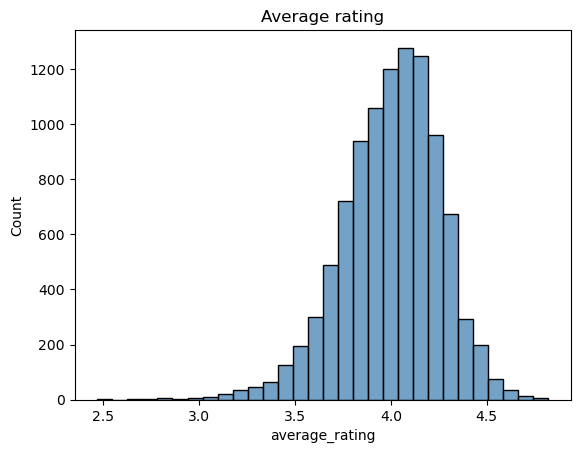

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(books["average_rating"], bins=30, color="steelblue")
plt.title("Average rating")
plt.show()


In [5]:
tags_path = glob.glob(os.path.join(path, "**", "tags.csv"), recursive=True)[0]
book_tags_path = glob.glob(os.path.join(path, "**", "book_tags.csv"), recursive=True)[0]
tags = pd.read_csv(tags_path)
book_tags = pd.read_csv(book_tags_path)
book_tags = book_tags.merge(tags, on="tag_id")
book_tags = book_tags[book_tags["tag_name"].str.fullmatch(r"[a-z][a-z\-]{2,24}")]
shelf = ["to-read", "favorites", "currently-reading", "owned", "books-i-own", "favourites", "kindle", "ebook", "ebooks", "my-books", "to-buy", "owned-books"]
book_tags = book_tags[~book_tags["tag_name"].isin(shelf)]
top_tags = book_tags.sort_values("count", ascending=False).groupby("goodreads_book_id").head(6)
tag_text = top_tags.groupby("goodreads_book_id")["tag_name"].agg(" ".join)
books = books.merge(tag_text.rename("tags"), left_on="book_id", right_index=True)
books[["title", "authors", "tags"]].head()


,title,authors,tags
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,young-adult fiction dystopian dystopia fantasy...
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",fantasy young-adult fiction harry-potter serie...
2,"Twilight (Twilight, #1)",Stephenie Meyer,young-adult fantasy vampires fiction paranorma...
3,To Kill a Mockingbird,Harper Lee,classics classic historical-fiction school lit...
4,The Great Gatsby,F. Scott Fitzgerald,classics fiction classic literature school his...


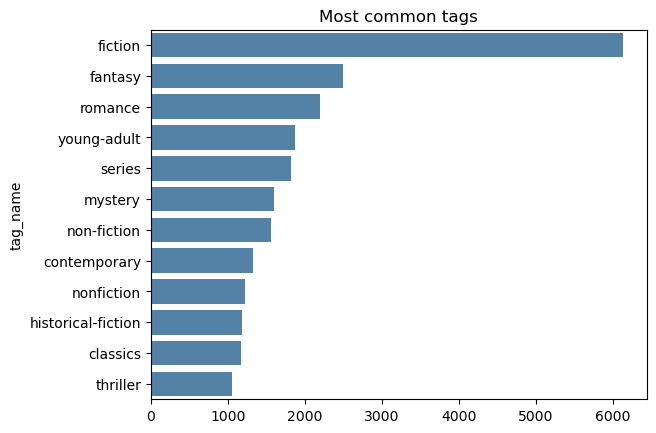

In [6]:
top = top_tags["tag_name"].value_counts().head(12)
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title("Most common tags")
plt.show()


In [7]:
books = books.sample(2500, random_state=42)
books["year"] = books["original_publication_year"].fillna(0).astype(int).astype(str)
books["text"] = (
    books["title"].fillna("")
    + " | " + books["authors"].fillna("")
    + " | " + books["year"]
    + " | rating " + books["average_rating"].astype(str)
    + " | " + books["tags"].fillna("")
)
books["text"].head()


6252    Scion of Ikshvaku (RamChandra, #1) | Amish Tri...
4684    Canada | Richard Ford | 2012 | rating 3.49 | f...
1731    The Man in the Brown Suit | Agatha Christie | ...
4742    Twilight and Philosophy: Vampires, Vegetarians...
4521    Saga, Vol. 5 (Saga, #5) | Brian K. Vaughan, Fi...
Name: text, dtype: object

In [8]:
import chromadb

col = chromadb.Client().get_or_create_collection("books")
col.add(ids=books["book_id"].astype(str).tolist(), documents=books["text"].tolist())
print(col.count())


2500


In [9]:
query = "I want a sad literary novel, not a long fantasy series"
found = col.query(query_texts=[query], n_results=5)
print("\n\n".join(found["documents"][0]))


The Well of Lost Plots (Thursday Next #3) | Jasper Fforde | 2003 | rating 4.09 | fantasy humor fiction series books-about-books science-fiction

The Wishing Spell (The Land of Stories, #1) | Chris Colfer, Brandon Dorman | 2012 | rating 4.21 | middle-grade fantasy childrens young-adult series fiction

The End of Mr. Y | Scarlett Thomas | 2006 | rating 3.79 | fantasy fiction literature narrativa modern science-fiction

The Queen of the Tearling (The Queen of the Tearling, #1) | Erika Johansen | 2014 | rating 4.02 | fantasy young-adult fiction dystopian series dystopia

The Dead | James Joyce | 1914 | rating 4.09 | classics short-stories fiction literature classic irish


# OpenRouter key

Write the key in `AIAgents/.env`, on the same line, right after the equals sign. Then run the next cell. It reads that file. The agent cells below use it.


In [10]:
from pathlib import Path

env_path = next(p for p in [Path("AIAgents/.env"), Path(".env")] if p.exists())
os.environ["OPENROUTER_API_KEY"] = env_path.read_text(encoding="utf-8").split("=", 1)[1].strip().strip('"').strip("'")
print("key loaded from", env_path)


key loaded from .env


In [11]:
import json
import requests
from IPython.display import Markdown

def book_agent(query):
    found = col.query(query_texts=[query], n_results=5)
    context = "\n".join(found["documents"][0])
    prompt = (
        "You are a book advisor. Use ONLY the books in the context.\n"
        "Format: ## Picks then a bullet for each book with the title and why it fits.\n\n"
        "Context:\n" + context + "\n\nReader:\n" + query
    )
    response = requests.post(
        url="https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": "Bearer " + os.environ["OPENROUTER_API_KEY"],
            "Content-Type": "application/json",
        },
        data=json.dumps({
            "model": "nvidia/nemotron-3-super-120b-a12b:free",
            "messages": [{"role": "user", "content": prompt}],
        }),
    )
    text = response.json()["choices"][0]["message"]["content"]
    return Markdown(text)

book_agent(query)


## Picks
- The Dead by James Joyce – a poignant, melancholy short story that explores regret, loss, and the quiet sadness of everyday life; it is literary fiction and not part of a fantasy series.

In [12]:
book_agent("A highly rated children's book")


## Picks
- The One and Only Ivan – Rated 4.24, this middle‑grade novel is celebrated for its touching story and strong appeal to children.  
- Where the Mountain Meets the Moon – Also rated 4.24, this fantasy tale blends adventure and cultural folklore, making it a highly acclaimed children’s pick.  
- Pictures of Hollis Woods – With a solid 4.0 rating, this young‑adult realistic‑fiction novel offers a compelling, heartfelt narrative suited for older children.

# Conclusion

I plotted the rating distribution and the common reader tags, then indexed 2500 books. Each document is the title, author, year, rating and a few tags. Chroma embeds that text and retrieves the five closest books. That embedding step is the deep learning in this project. The agent sends only those five rows to OpenRouter. The chat model is nvidia/nemotron-3-super-120b-a12b:free. It writes the picks from that context. The key is read from AIAgents/.env. The collection lives in the kernel session, so the index cell has to run again after a restart.
